# Noise and Numeric Instability

In our previous notebooks we have established the Matrix Pencil method as both a means of reconstructing resonances and as a means of phase correction. However, this method of phase correction has - so far- been restricted to clean spectra, with no noise. Real data has a substantial noise component. We have explored various methods to limit the impact of nosie in resoannce reconstruction but we do not yet know how deeply this effects phase estiamtion, and the differences we may need to make to account for this. How well can our phase correction do for a busy signal with a realistic signal:noise ratio? 

After we determine this, we will use our method on real NMR data. Testing this isn't too difficult. We will generate the same spectra with $K = 30$ and increase the noise, keeping everything else equal. We will see how the accuracy is impacted.

In [2]:
# Imports and Set-up

import pade_utils as pdu
import matplotlib.pyplot as plt
import numpy as np

In [2]:
K = 30
N = 400

noise_values = np.arange(0, 0.51, 0.025)

errors = []

for noise in noise_values:

    error_n = []

    for seed in range(30):

        rng = np.random.default_rng(seed)

        p0, p1 = rng.uniform(0, 2*np.pi, size=2)

        phased_fid = pdu.generate_synthetic_signal(order=K, noise_level=noise, tmax=N, seed=seed, p0=p0, p1=p1)

        try:
            p0_est, p1_est = pdu.retrieve_phases(phased_fid, order=K, n_datapoints=N, method='linear')

            p0_err = np.abs(np.angle(np.exp(1j * (p0_est - p0))))
            p1_err = np.abs(p1_est - p1)

            error_n.append((p0_err, p1_err))

        except np.linalg.LinAlgError:
            error_n.append((np.nan, np.nan))

    errors.append(error_n)
    #print(f"Noise = {noise:.3f} finished...")

errors = np.asarray(errors)

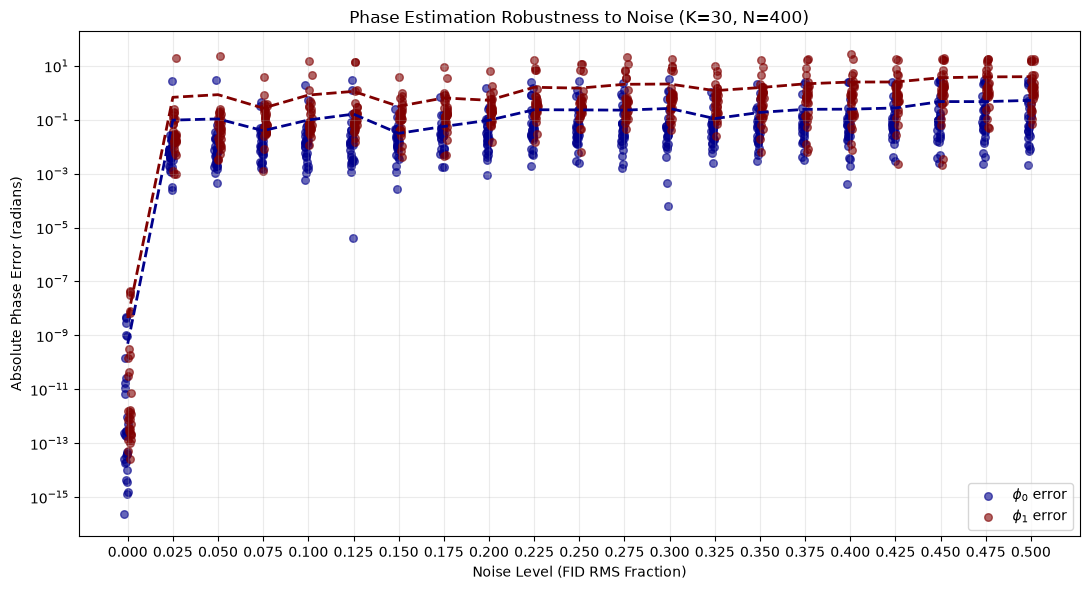

In [3]:
import numpy as np
import matplotlib.pyplot as plt

errors = np.asarray(errors)

mean_errors = np.nanmean(errors, axis=1)
median_errors = np.nanmedian(errors, axis=1)
max_errors = np.nanmax(errors, axis=1)
p90_errors = np.nanpercentile(errors, 90, axis=1)

for i, noise in enumerate(noise_values):

    failures = np.sum(np.isnan(errors[i, :, 0]))

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(18)

for i, noise in enumerate(noise_values):

    n_seeds = errors.shape[1]

    jitter = rng.uniform(-0.001, 0.001, n_seeds)

    ax.scatter(noise + jitter - 0.001, errors[i, :, 0], color="darkblue", alpha=0.6, s=30, label=r"$\phi_0$ error" if i == 0 else None)
    ax.scatter(noise + jitter + 0.001, errors[i, :, 1], color="maroon", alpha=0.6, s=30, label=r"$\phi_1$ error" if i == 0 else None)

ax.plot(noise_values, mean_errors[:, 0], color="darkblue", linestyle="--", linewidth=2)
ax.plot(noise_values, mean_errors[:, 1], color="maroon", linestyle="--", linewidth=2)

ax.set_yscale("log")

ax.set_xticks(noise_values)
ax.set_xlabel("Noise Level (FID RMS Fraction)")
ax.set_ylabel("Absolute Phase Error (radians)")
ax.set_title(f"Phase Estimation Robustness to Noise (K={K}, N={N})")

ax.legend()
ax.grid(alpha=0.25, which="both")

plt.tight_layout()
plt.show()

There is clearly stuff to dig into here, but before we do that we need to answer a critical question. For some fo the noise values right now, the 90th percentile error is $>2 \pi$. This is an issue because in reality phase wraps around. It is not periodic, and we cannot be more than $2 \pi$ radians away from the actual phase. Really, we cannot be more than $\pi$ radians away from the phase in *some* direction. We need to inspect how our errors are coming unravelled ans olve this, in order to get a better picture of what our actual errors may look like. Let's define our more sophisticated wrapping.

Initially, we take some bounds, where we expect to find our optimal $\phi_1$. Here we know the synthetic signals have $0 \leq \phi_1 < 2 \pi$, but for NMR signals in general this is not always the case. But how do we find this optimal $\phi_1$? The phase at current is: $$\phi_k = \phi_0 + \phi_1 f_k$$ If we guess $\phi_1$ and subtract it from each point, on avergae, summing them will do basically nothing. Each vector is turned by some random amount, some point up and some down and sum to about $0$. But if our guess is $\approx \phi_1$ then subtracting it gives $$\phi_k = \phi_0 + (\phi_1 - \phi_1)f$$ $$\phi_k = \phi_0$$ Every resonance now has the same phase! They point in the same direction! Therefore summing them gives a big peak when we get to this, and it's easy to find $\phi_0$ as it's the phase left on all the vectors! We can reduce a 2D search down to only one dimension, and with the added benefit that the circular wrapping of the search comes completely naturally. It produces one optimum value for $\phi_1$, which we can implement.

In [3]:
def circular_regression(z_k, d_k, bounds=(0*np.pi, 2*np.pi)):

    frequencies = np.angle(z_k) / (2*np.pi)
    phases = np.angle(d_k)
    weights = np.abs(d_k)**2

    def objective(p1):
        return -np.abs(np.sum(weights * np.exp(1j * (phases - p1 * frequencies))))

    grid = np.linspace(*bounds, 1001)
    losses = np.array([objective(p1) for p1 in grid])

    best = np.argmin(losses)

    left = grid[max(best - 1, 0)]
    right = grid[min(best + 1, len(grid) - 1)]

    result = minimize_scalar(objective, bounds=(left, right), method="bounded", options={"xatol": 1e-12})

    candidates = [bounds[0], bounds[1], result.x]
    p1_est = min(candidates, key=objective)

    p0_est = np.angle(np.sum(weights * np.exp(1j * (phases - p1_est * frequencies))))

    return p0_est, p1_est

Now let's run the exact same experiment with circular regression instead.


In [5]:
K = 30
N = 400

noise_values = np.arange(0, 0.51, 0.025)

errors = []

for noise in noise_values:

    error_n = []

    for seed in range(30):

        rng = np.random.default_rng(seed)

        p0, p1 = rng.uniform(0, 2*np.pi, size=2)

        phased_fid = pdu.generate_synthetic_signal(order=K, noise_level=noise, tmax=N, seed=seed, p0=p0, p1=p1)

        try:
            p0_est, p1_est = pdu.retrieve_phases(phased_fid, order=K, n_datapoints=N, method='circular')

            p0_err = np.abs(np.angle(np.exp(1j * (p0_est - p0))))
            p1_err = np.abs(p1_est - p1)

            error_n.append((p0_err, p1_err))

        except np.linalg.LinAlgError:
            error_n.append((np.nan, np.nan))

    errors.append(error_n)
    #print(f"Noise = {noise:.3f} finished...")

errors = np.asarray(errors)

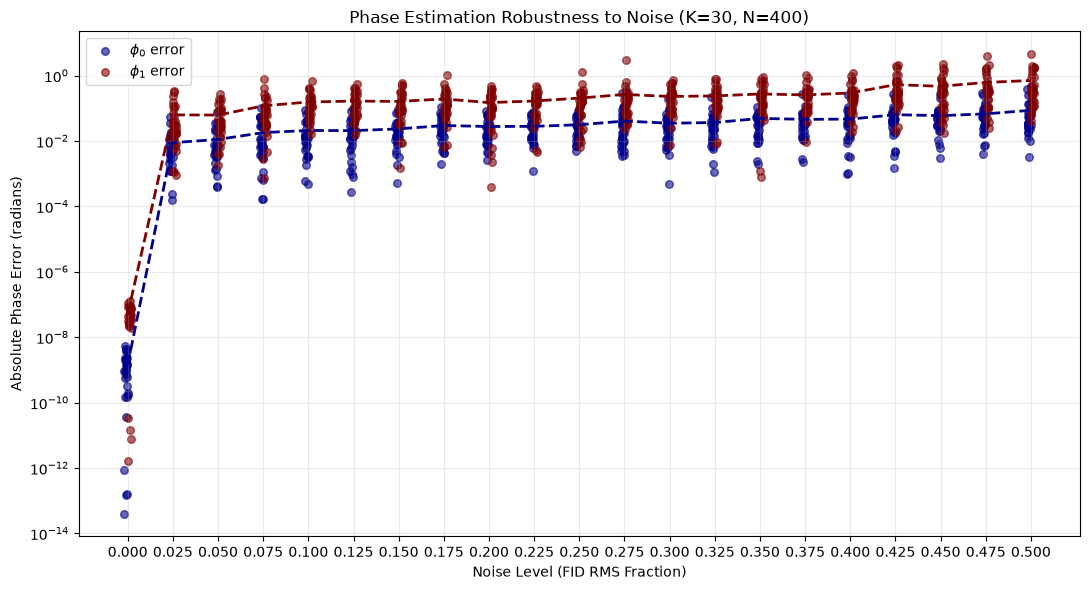

In [6]:
import numpy as np
import matplotlib.pyplot as plt

errors = np.asarray(errors)

mean_errors = np.nanmean(errors, axis=1)
median_errors = np.nanmedian(errors, axis=1)
max_errors = np.nanmax(errors, axis=1)
p90_errors = np.nanpercentile(errors, 90, axis=1)

for i, noise in enumerate(noise_values):

    failures = np.sum(np.isnan(errors[i, :, 0]))

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(18)

for i, noise in enumerate(noise_values):

    n_seeds = errors.shape[1]

    jitter = rng.uniform(-0.001, 0.001, n_seeds)

    ax.scatter(noise + jitter - 0.001, errors[i, :, 0], color="darkblue", alpha=0.6, s=30, label=r"$\phi_0$ error" if i == 0 else None)
    ax.scatter(noise + jitter + 0.001, errors[i, :, 1], color="maroon", alpha=0.6, s=30, label=r"$\phi_1$ error" if i == 0 else None)

ax.plot(noise_values, mean_errors[:, 0], color="darkblue", linestyle="--", linewidth=2)
ax.plot(noise_values, mean_errors[:, 1], color="maroon", linestyle="--", linewidth=2)

ax.set_yscale("log")

ax.set_xticks(noise_values)
ax.set_xlabel("Noise Level (FID RMS Fraction)")
ax.set_ylabel("Absolute Phase Error (radians)")
ax.set_title(f"Phase Estimation Robustness to Noise (K={K}, N={N})")

ax.legend()
ax.grid(alpha=0.25, which="both")

plt.tight_layout()
plt.show()

In [7]:
K, N = 30, 400
noise_values = np.arange(0, 0.51, 0.025)
n_seeds = 30

errors = np.full((len(noise_values), n_seeds, 2), np.nan)
f = np.linspace(-0.5, 0.5, 1000)

for i, noise in enumerate(noise_values):
    for seed in range(n_seeds):

        rng = np.random.default_rng(seed)
        p0, p1 = rng.uniform(0, 2*np.pi, 2)

        fid = pdu.generate_synthetic_signal(order=K, tmax=N, noise_level=noise,p0=p0, p1=p1, seed=seed)

        for j, method in enumerate(["linear", "circular"]):
            try:
                p0_est, p1_est = pdu.retrieve_phases(fid, order=K, n_datapoints=N, method=method)
                phase_error = np.angle(np.exp(1j * ((p0_est - p0) + (p1_est - p1)*f)))
                errors[i, seed, j] = np.sqrt(np.mean(phase_error**2))

            except (np.linalg.LinAlgError, ValueError):
                pass

In [1]:
plt.figure(figsize=(10, 6))

for j, (method, color) in enumerate([("Linear", "darkblue"), ("Circular", "maroon")]):
    
    median = np.nanmedian(errors[:, :, j], axis=1)
    p90 = np.nanpercentile(errors[:, :, j], 90, axis=1)

    plt.plot(noise_values, median, "o-", color=color,label=f"{method} median")
    plt.plot(noise_values, p90, "--", color=color,label=f"{method} 90th percentile")

plt.xlabel("Relative Noise Level")
plt.ylabel("Spectral RMS Phase Error (radians)")
plt.title(f"Linear vs Circular Phase Regression (K={K}, N={N})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

This is really promising! It's interesting to note that linear actually does outperform circular for clean signals, but never by more than $0.00001$°. This is -frankly- an unecessary level of precision for phase values in almost all circumstances, and limiting catastrophic rephasing alongside better performance for higher noise values means it is a sensible default to use, and will be the standard from here on out. The next step is to focus a little more on SVD truncation, is there an optimal value- do we need all the resonances? This is what we will explore. We want to know whether our phase corrector can work on real, noisy signals, what aprameters improve this estimate, the computational effciency, and where it fails. 


We would like to understand how noise scales with both:
- The number of datapoints used $N$ (how truncated a signal can we get away with)
- The order $K$ of the reconstruction, with extra dimensions eliminated through SVD


Let's start with SVD truncation. We will generate a signal with a known $K$, and construct it explicitly varying the model order. 

In [13]:
K, N = 30, 400
ranks = [10, 15, 20, 25, 30, 35, 40, 50]
rank_noise_values = [0.0, 0.1, 0.3]
n_seeds = 100

rank_errors = np.full((len(rank_noise_values), len(ranks), n_seeds), np.nan)
f = np.linspace(-0.5, 0.5, 1000)

for i, noise in enumerate(rank_noise_values):
    for seed in range(n_seeds):

        rng = np.random.default_rng(seed)
        p0, p1 = rng.uniform(0, 2*np.pi, 2)

        fid = pdu.generate_synthetic_signal(order=K, tmax=N, noise_level=noise,p0=p0, p1=p1, seed=seed)

        for j, rank in enumerate(ranks):
            try:
                p0_est, p1_est = pdu.retrieve_phases(fid, order=rank, n_datapoints=N, method='circular')
                phase_error = np.angle(np.exp(1j * ((p0_est - p0) + (p1_est - p1)*f)))
                rank_errors[i, j, seed] = np.sqrt(np.mean(phase_error**2))

            except (np.linalg.LinAlgError, ValueError):
                pass

    print(f"Noise {noise:.0%} complete")

Noise 0% complete
Noise 10% complete
Noise 30% complete


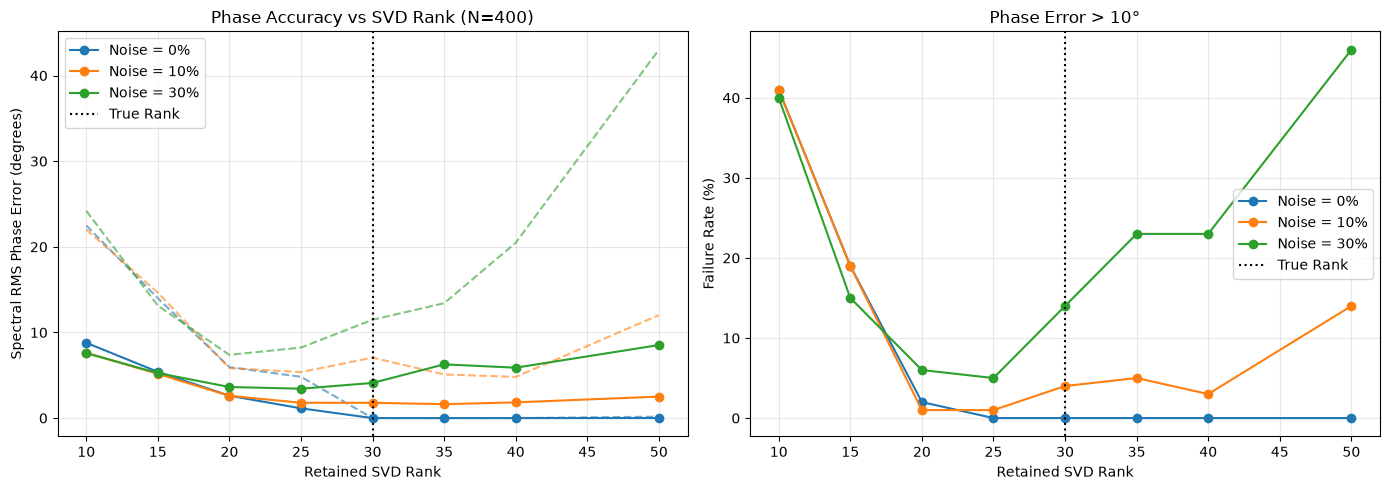

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, noise in enumerate(rank_noise_values):

    median = np.degrees(np.nanmedian(rank_errors[i], axis=1))
    p90 = np.degrees(np.nanpercentile(rank_errors[i], 90, axis=1))

    failures = 100 * np.mean((np.degrees(rank_errors[i]) > 10) | ~np.isfinite(rank_errors[i]),axis=1)

    line, = axes[0].plot(ranks, median, "o-", label=f"Noise = {noise:.0%}")
    axes[0].plot(ranks, p90, "--", color=line.get_color(), alpha=0.6)
    axes[1].plot(ranks, failures, "o-", label=f"Noise = {noise:.0%}")

for ax in axes:
    ax.axvline(K, color="black", linestyle=":", label="True Rank")
    ax.set_xlabel("Retained SVD Rank")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Spectral RMS Phase Error (degrees)")
axes[0].set_title(f"Phase Accuracy vs SVD Rank (N={N})")

axes[1].set_ylabel("Failure Rate (%)")
axes[1].set_title("Phase Error > 10°")

plt.tight_layout()
plt.show()

This is an interesting find! For a perfect, noiseless signal this is what we expect, the error steadily decreases until we hit the rquisite number of resonances, but then stabilises. For noisy (real) signals though, the median reaches it's minimum somewhat earlier, at around 25, before steadily incrasing as more and more spurious noisy signals are factored into the phase. Perhaps more significantly though it our robustness. Even for 30% noise, we are only > 10 degrees off for ~ 5% of signals at 25, but this has more than doubled by 30, and at $K = 50$ we see more than half of the phase errors being wrong. The best option seems to be lightly underestimating the true K, only using the strongest signals to find this happy medium, and limit the worst case scenarios. For all of these tests however, $N$ has been fixed at $400$. This was done in order to prevent introducing a second variable, but $400$ datapoints is $20 \times$ the minimum for $10$ datapoints, but is only $4 \times$ the time we get to $50$. Let's try and test the impact of increasing the number of datapoints we give alongside the SVD rank.

In [15]:
K = 30
N_values = [80, 100, 150, 200, 300, 400, 600, 800]
N_ranks = [15, 20, 25, 30, 35]
N_noise_values = [0.1, 0.3]
n_seeds = 100

N_errors = np.full((len(N_noise_values), len(N_values), len(N_ranks), n_seeds),np.nan)

f = np.linspace(-0.5, 0.5, 1000)

for i, noise in enumerate(N_noise_values):
    for seed in range(n_seeds):

        rng = np.random.default_rng(seed)
        p0, p1 = rng.uniform(0, 2*np.pi, 2)

        fid = pdu.generate_synthetic_signal(order=K, tmax=max(N_values), noise_level=noise,p0=p0, p1=p1, seed=seed)

        for j, N in enumerate(N_values):
            for k, rank in enumerate(N_ranks):

                try:
                    p0_est, p1_est = pdu.retrieve_phases(fid, order=rank, n_datapoints=N, method='circular')
                    phase_error = np.angle(np.exp(1j * ((p0_est - p0) + (p1_est - p1)*f)))

                    N_errors[i, j, k, seed] = np.sqrt(np.mean(phase_error**2))

                except (np.linalg.LinAlgError, ValueError):
                    pass

    print(f"Noise {noise:.0%} complete")

Noise 10% complete
Noise 30% complete


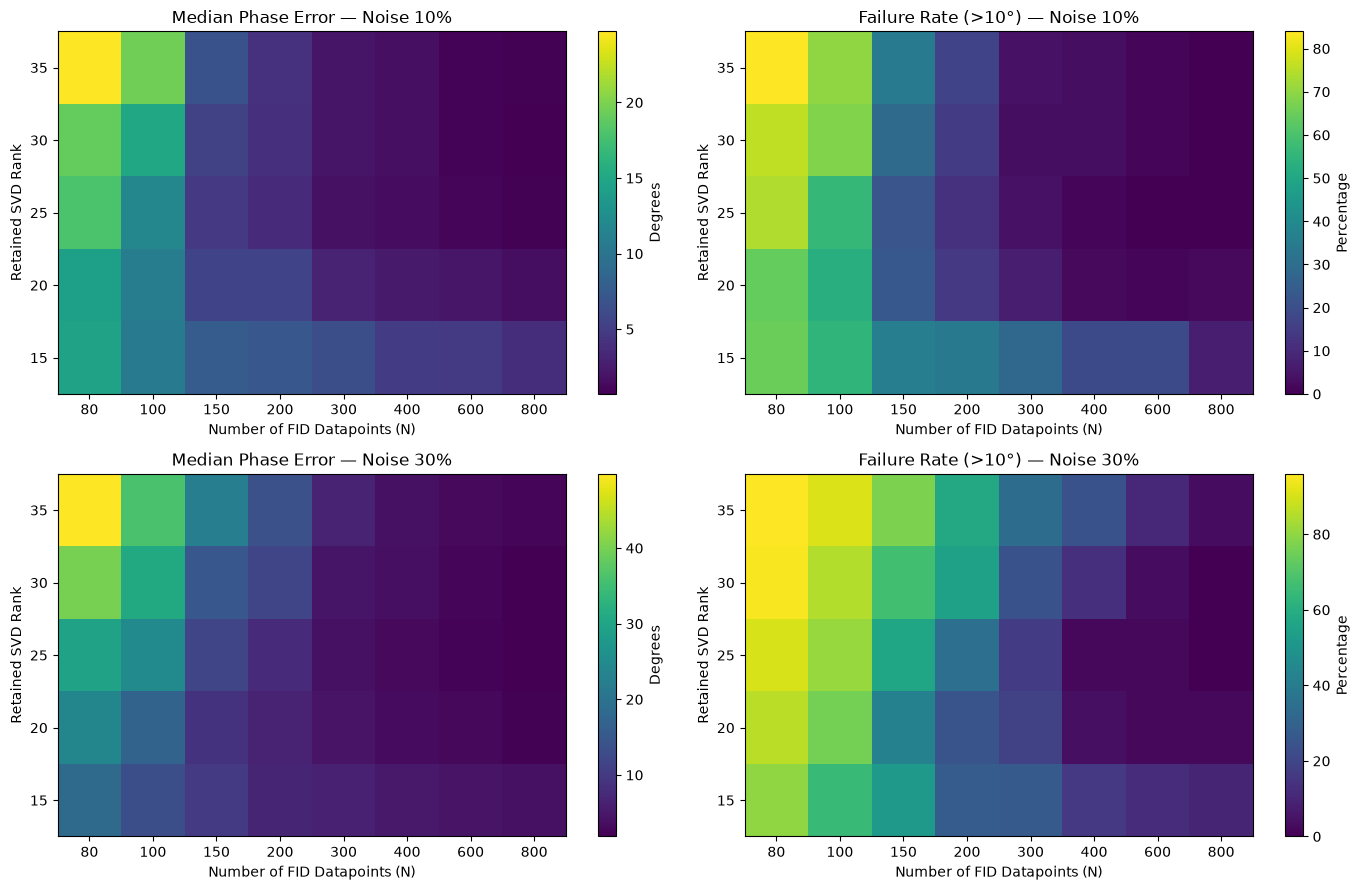

In [16]:
median_errors = np.degrees(np.nanmedian(N_errors, axis=3))

failure_rates = 100 * np.mean((np.degrees(N_errors) > 10) | ~np.isfinite(N_errors),axis=3)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, noise in enumerate(N_noise_values):

    for j, (data, title, label) in enumerate([(median_errors[i], "Median Phase Error", "Degrees"), (failure_rates[i], "Failure Rate (>10°)", "Percentage")]):

        ax = axes[i, j]

        im = ax.imshow(data.T, origin="lower", aspect="auto")

        ax.set_xticks(range(len(N_values)))
        ax.set_xticklabels(N_values)

        ax.set_yticks(range(len(N_ranks)))
        ax.set_yticklabels(N_ranks)

        ax.set_xlabel("Number of FID Datapoints (N)")
        ax.set_ylabel("Retained SVD Rank")
        ax.set_title(f"{title} — Noise {noise:.0%}")

        fig.colorbar(im, ax=ax, label=label)

plt.tight_layout()
plt.show()

This tells us quite a clear story! More datapoints helps essentially universally (though there is obviously computational cost), whereas SVD rank is a more complex story, where we would like to slightly underestimate the resonances, or only use the stronger ones. Of course, for an actual spectra, critically, we do not know how many resonances there are, and the autoamtic determination of some minimum resonances will be critical. This will be the next step in actually improving the algorithm, but before that, we would like to test this on real FIDs from real spectra- in order to ensure that it works. 